## 1. Install Required Libraries
First, ensure you have the necessary libraries installed. If you haven't installed FastAI and other dependencies yet, you can do so using pip:

````
pip install fastai
pip install segmentation-models-pytorch
````


## 2. Import Libraries
Begin by importing the required libraries:

In [1]:
from fastai.vision.all import *
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from PIL import Image
from fastai.vision.all import get_image_files, PILImage, PILMask
from torch import nn

## 3. Define the Data Path
Set the path to your organized dataset:

In [4]:
# Example usage
path = Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment')
    #'/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/organized_dataset_segment')

# Sample image file
image_file = path / 'images' / 'valid' / 'patient_4_slice_15.png'

## 4. Define the Classes
Specify the classes for segmentation. Based on your description, you have 4 classes (including background). Modify the class names as per your labels.

In [6]:
classes = ['background', 'cancer']

## 5. Create Helper Function for Mask Names
Since your mask filenames append _label to the image filenames, create a helper function to convert image filenames to mask filenames:

In [7]:
import numpy as np
from PIL import Image as PILImage

def image_to_mask(fname):
    """
    Given an image file path, returns the corresponding mask file path.
    Assumes masks are stored in 'masks/<split>/filename_label.png'
    """
    # Extract the split name (e.g., 'train', 'val', 'test') from the image path
    split = fname.parent.name  # 'train', 'val', or 'test'
    
    # Navigate to the 'organized_dataset_segment' directory
    base_path = fname.parent.parent.parent  

    # Construct the mask path
    mask_path = base_path / 'masks' / split / f"{fname.stem}_label{fname.suffix}"

    return mask_path

In [8]:
# Get corresponding mask path
mask_file = image_to_mask(image_file)
print(mask_file)

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/masks/valid/patient_4_slice_15_label.png


In [9]:
# List subdirectories under images
image_subdirs = list((path / 'images').iterdir())
print("Image Subdirectories:", image_subdirs)

# List subdirectories under masks
mask_subdirs = list((path / 'masks').iterdir())
print("Mask Subdirectories:", mask_subdirs)

Image Subdirectories: [Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/train'), Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/valid'), Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test')]
Mask Subdirectories: [Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/masks/train'), Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/masks/valid'), Path('/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/masks/test')]


## 6. Define the DataBlock

In [10]:
def get_images_with_masks(p):
    """
    Retrieves all image files from 'images/train/' and 'images/valid/' directories
    that have corresponding masks.
    """
    train_images = list((p / 'images/train').rglob('*.*'))
    valid_images = list((p / 'images/valid').rglob('*.*'))
    # Include desired image extensions
    allowed_exts = ['.png', '.jpg', '.jpeg']
    return [
        f for f in train_images + valid_images
        if f.suffix.lower() in allowed_exts and image_to_mask(f).exists()
    ]

In [11]:
# Define the DataBlock for training and validation
segmentation_block = DataBlock(
    blocks=(ImageBlock, MaskBlock(codes=classes)),  # Use MaskBlock with defined classes
    get_items=lambda p: get_image_files(p / 'images/train') + get_image_files(p / 'images/valid'),
    get_y=image_to_mask,
    splitter=FuncSplitter(lambda x: x.is_relative_to(path / 'images/valid')),  # Assign 'valid' to validation set
    batch_tfms=[
        Resize(256, method='pad', pad_mode='zeros'),
        *aug_transforms(size=256)
    ],
    item_tfms=Resize(256)
)

In [12]:
# 7. Verify the splits have data
dsets = segmentation_block.datasets(path, verbose=True)
print(f"Number of training items: {len(dsets.train)}")  # Should be 707
print(f"Number of validation items: {len(dsets.valid)}")  # Should be 474

Found 168 items
2 datasets of sizes 126,42
Setting up Pipeline: PILBase.create
Setting up Pipeline: image_to_mask -> PILBase.create
Number of training items: 126
Number of validation items: 42


## 7. Create DataLoaders for Training and Validation
Initialize the DataLoaders without the test set:

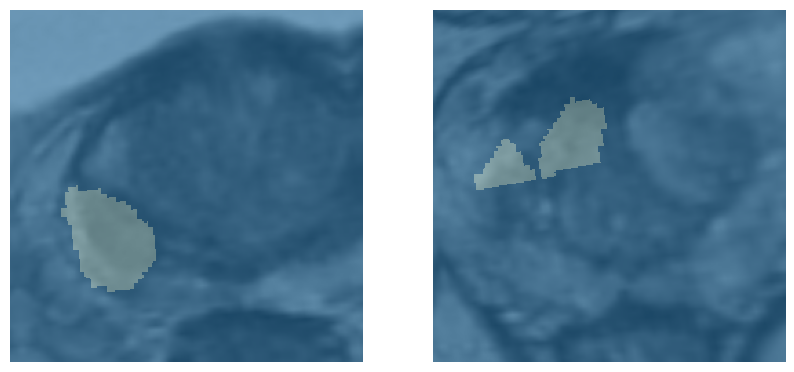

In [13]:
# Create DataLoaders for training and validation
dls = segmentation_block.dataloaders(path, bs=2)

# Optional: Inspect a Batch
dls.show_batch(max_n=2, figsize=(10, 10), vmin=0, vmax=1)

In [15]:
# Inspect a single batch from the training DataLoader
for images, masks in dls.train:
    print(f"Images shape: {images.shape}")  # Expected: (batch_size, 3, 256, 256)
    print(f"Masks shape: {masks.shape}")    # Expected: (batch_size, 256, 256)
    print(f"Masks dtype: {masks.dtype}")    # Expected: torch.long
    break

Images shape: torch.Size([2, 3, 256, 256])
Masks shape: torch.Size([2, 256, 256])
Masks dtype: torch.int64


## Data Loader for testing

In [16]:
# Define the DataBlock for the test set
test_segmentation_block = DataBlock(
    blocks=(ImageBlock, MaskBlock(codes=classes)),
    get_items=lambda p: get_image_files(p / 'images/test'),
    get_y=image_to_mask,
    splitter=FuncSplitter(lambda x: False),  # Assign all to training within this DataBlock
    batch_tfms=[
        Resize(256, method='pad', pad_mode='zeros'),
    ],
    item_tfms=Resize(256)
)

Found 38 items
2 datasets of sizes 38,0
Setting up Pipeline: PILBase.create
Setting up Pipeline: image_to_mask -> PILBase.create
Number of test items: 38


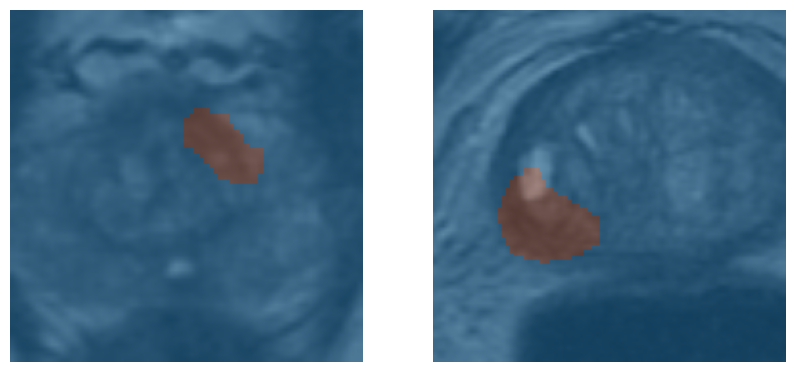

In [17]:
# Create DataLoaders for the test set
test_dls = test_segmentation_block.dataloaders(path, bs=2)

# Let's verify the test DataLoader has data and how many items it has
test_dsets = test_segmentation_block.datasets(path, verbose=True)
print(f"Number of test items: {len(test_dsets.train)}")  # Should be 38

# Optional: Inspect a Test Batch
test_dls.show_batch(max_n=2, figsize=(10, 10))

## 6. Define Metrics
For a two-class segmentation task, we use the Dice coefficient:

In [20]:
import torch
from fastai.metrics import Metric

class BackgroundAcc(Metric):
    def reset(self):
        self.correct = 0
        self.total = 0

    def accumulate(self, learn):
        y_pred, y_true = learn.pred, learn.y
        # y_pred shape: [batch, 2, H, W]
        # y_true shape: [batch, 1, H, W]
        
        y_pred_classes = y_pred.argmax(dim=1)  # Shape: [batch, H, W]
        y_true = y_true.squeeze(1)             # Shape: [batch, H, W]
        
        # Background is class 0
        background_correct = (y_pred_classes == 0) & (y_true == 0)
        background_total = (y_true == 0).sum().item()
        
        self.correct += background_correct.sum().item()
        self.total += background_total

    @property
    def value(self):
        return self.correct / self.total if self.total > 0 else 0.0

class CancerAcc(Metric):
    def reset(self):
        self.correct = 0
        self.total = 0

    def accumulate(self, learn):
        y_pred, y_true = learn.pred, learn.y
        y_pred_classes = y_pred.argmax(dim=1)
        y_true = y_true.squeeze(1)
        
        # Cancer is class 1
        cancer_correct = (y_pred_classes == 1) & (y_true == 1)
        cancer_total = (y_true == 1).sum().item()
        
        self.correct += cancer_correct.sum().item()
        self.total += cancer_total

    @property
    def value(self):
        return self.correct / self.total if self.total > 0 else 0.0

class BackgroundDice(Metric):
    def reset(self):
        self.intersection = 0.0
        self.union = 0.0

    def accumulate(self, learn):
        y_pred, y_true = learn.pred, learn.y
        y_pred_classes = y_pred.argmax(dim=1).float()
        y_true = y_true.squeeze(1).float()
        
        # Background is class 0
        background_pred = (y_pred_classes == 0).float()
        background_true = (y_true == 0).float()
        
        # Intersection and union
        intersection = (background_pred * background_true).sum().item()
        union = background_pred.sum().item() + background_true.sum().item()
        
        self.intersection += intersection
        self.union += union

    @property
    def value(self):
        return (2 * self.intersection) / (self.union + 1e-8) if self.union > 0 else 0.0

class CancerDice(Metric):
    def reset(self):
        self.intersection = 0.0
        self.union = 0.0

    def accumulate(self, learn):
        y_pred, y_true = learn.pred, learn.y
        y_pred_classes = y_pred.argmax(dim=1).float()
        y_true = y_true.squeeze(1).float()
        
        # Cancer is class 1
        cancer_pred = (y_pred_classes == 1).float()
        cancer_true = (y_true == 1).float()
        
        # Intersection and union
        intersection = (cancer_pred * cancer_true).sum().item()
        union = cancer_pred.sum().item() + cancer_true.sum().item()
        
        self.intersection += intersection
        self.union += union

    @property
    def value(self):
        return (2 * self.intersection) / (self.union + 1e-8) if self.union > 0 else 0.0

## Weighted loss function

In [21]:
# Calculate class weights based on your dataset
class_weights = torch.tensor([1.0, 3.0])

# Define the loss function
loss_func = nn.CrossEntropyLoss(weight=class_weights)

## 7. Initialize the Learner with a Supported Encoder
Using a supported encoder like resnet34 ensures compatibility and simplifies the setup.

In [22]:
from fastai.metrics import Dice  # Ensure this is imported
from SemTorch.semtorch.learner import get_segmentation_learner

# Define the custom metrics
metrics = [
    Dice(),           # Fastai's built-in overall Dice
    BackgroundAcc(),            # Custom Background Accuracy
    CancerAcc(),                # Custom Cancer Accuracy
    BackgroundDice(),           # Custom Background Dice
    CancerDice()                # Custom Cancer Dice
]

print(len(classes))

2


/home/marina/anaconda3/envs/semtorch/lib/python3.9/site-packages/torch/nn/_reduction.py:42: UserWarning: size_average and reduce args will be deprecated, please use reduction='mean' instead.
  warnings.warn(warning.format(ret))


'\n# Initialize the learner with the updated metrics\nlearn_maria = get_segmentation_learner(\n    dls, number_classes=len(classes),\n    segmentation_type=\'multiclass\',\n    architecture_name="unet",\n    backbone_name="hrnet_w30",\n    loss_func=loss_func,\n    metrics=metrics,\n    pretrained=True,\n    normalize=True,\n    wd=1e-2\n)'

In [23]:
from fastai.vision.all import *
import matplotlib.pyplot as plt

# Check unique values in a batch of masks
images, masks = dls.one_batch()
print("Unique mask values:", masks.unique())
print("Shape of masks:", masks.shape)
print("Shape of images:", images.shape)
print(f"dls len: {len(dls.train)}")
print(f"dls len: {len(dls.valid)}")

Unique mask values: TensorMask([0, 1])
Shape of masks: torch.Size([2, 256, 256])
Shape of images: torch.Size([2, 3, 256, 256])
dls len: 63
dls len: 21


In [24]:
callbacks = [
    EarlyStoppingCallback(monitor='cancer_dice', comp=np.greater, patience=3),
    SaveModelCallback(monitor='cancer_dice', comp=np.greater, fname='unet-model'),
    ReduceLROnPlateau(monitor='cancer_dice', comp=np.greater, patience=3)
]
opt = ranger
learn = unet_learner(dls, resnet34, self_attention=True, act_cls=Mish, opt_func=opt,metrics=metrics,cbs=callbacks)

## 8. Train the Model
Proceed to train your model using the fine_tune method.

SuggestedLRs(valley=0.0002290867705596611)

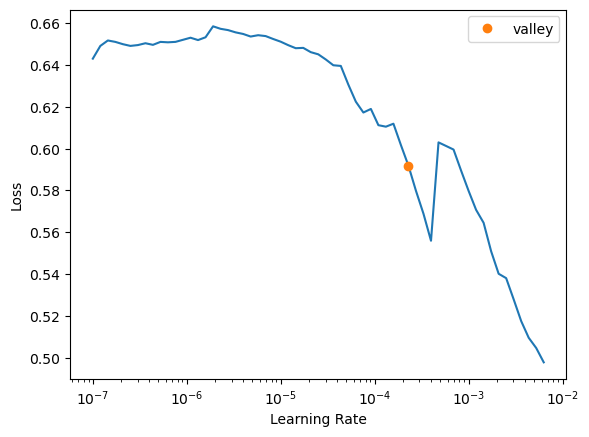

In [21]:
learn.lr_find()

In [ ]:
monitor_training = "valid_loss"
comp_training = np.less
monitor_evaluating = "dice"
comp_evaluating = np.greater
patient = 2
found_lr = 0.000229 #0.01096 #0.00524 #0.00912#0.0025

In [ ]:
fname = "checkpoints/2d_unet_onlypositives_before_unfreeze_new_metrics"

callbacksFitBeforeUnfreeze = [ShowGraphCallback(), 
                              EarlyStoppingCallback(monitor=monitor_training, comp=comp_training, patience=patient),
                              SaveModelCallback(monitor=monitor_training,comp=comp_training,every_epoch=False,fname=fname)]

### Train for 20 epochs

In [22]:
learn.fit_one_cycle(20, 0.000229)

epoch,train_loss,valid_loss,dice,background_acc,cancer_acc,background_dice,cancer_dice,time
0,0.488799,0.399947,0.000017,0.998714,0.000009,0.933000,0.000017,01:32
1,0.377909,0.322977,0.000000,0.999974,0.000000,0.933628,0.000000,01:35
2,0.325479,0.341814,0.000000,0.999995,0.000000,0.933638,0.000000,01:36
3,0.299863,0.283493,0.059122,0.999406,0.030589,0.935243,0.059122,01:36
4,0.296705,0.333736,0.406633,0.951877,0.341598,0.930717,0.406633,01:32
5,0.295677,0.281440,0.109974,0.998749,0.058699,0.936668,0.109974,01:35
6,0.302422,0.271278,0.000595,0.999988,0.000298,0.933653,0.000595,01:33
7,0.305845,0.286617,0.236314,0.995022,0.138681,0.939826,0.236314,01:36
8,0.281669,0.257858,0.333277,0.989441,0.214812,0.941850,0.333277,01:34
9,0.260763,0.242664,0.366771,0.987731,0.243950,0.942849,0.366771,01:36


Better model found at epoch 0 with valid_loss value: 0.39994680881500244.
Better model found at epoch 1 with valid_loss value: 0.32297664880752563.
Better model found at epoch 3 with valid_loss value: 0.28349271416664124.
Better model found at epoch 5 with valid_loss value: 0.28143951296806335.
Better model found at epoch 6 with valid_loss value: 0.2712783217430115.
Better model found at epoch 8 with valid_loss value: 0.25785836577415466.
Better model found at epoch 9 with valid_loss value: 0.24266397953033447.
Better model found at epoch 11 with valid_loss value: 0.24075673520565033.
Better model found at epoch 12 with valid_loss value: 0.23517756164073944.
Better model found at epoch 13 with valid_loss value: 0.22943666577339172.
Better model found at epoch 14 with valid_loss value: 0.22041338682174683.
Better model found at epoch 16 with valid_loss value: 0.21496550738811493.
Epoch 19: reducing lr to 2.922665580498739e-10
No improvement since epoch 16: early stopping


# unfreeze

In [25]:
learn.load("checkpoints/2dunet-model-after-unfreeze")
learn.unfreeze()

/home/marina/anaconda3/envs/semtorch/lib/python3.9/site-packages/fastai/learner.py:61: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")


[<fastai.metrics.Dice object at 0x7f53003938b0>, <__main__.BackgroundAcc object at 0x7f5300393280>, <__main__.CancerAcc object at 0x7f5300393130>, <__main__.BackgroundDice object at 0x7f5300393df0>, <__main__.CancerDice object at 0x7f5300393430>]


SuggestedLRs(valley=0.0002290867705596611)

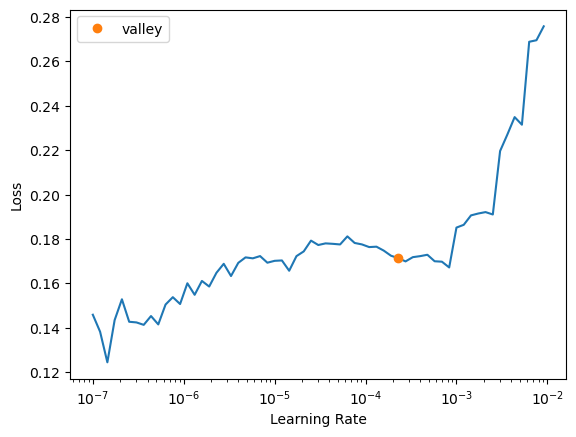

In [26]:
print(learn.recorder.metrics)
learn.lr_find(show_plot=True)

In [28]:
callbacksafterunfreeze = [
    EarlyStoppingCallback(monitor='cancer_dice', comp=np.greater, patience=3),
    SaveModelCallback(monitor='cancer_dice', comp=np.greater, fname='unet-model-unfrozen'),
    ReduceLROnPlateau(monitor='cancer_dice', comp=np.greater, patience=3)
]
learn.fit_one_cycle(10, 0.000229, cbs=callbacksafterunfreeze)

epoch,train_loss,valid_loss,dice,background_acc,cancer_acc,background_dice,cancer_dice,time


Better model found at epoch 0 with valid_loss value: 0.20240479707717896.
Better model found at epoch 0 with cancer_dice value: 0.6269002622862461.
Epoch 3: reducing lr to 2.0757808613122297e-05
Epoch 3: reducing lr to 2.0757808613122295e-06
No improvement since epoch 0: early stopping


## validation

In [29]:
def inspect_predictions(y_pred, y_true):
    print(f"y_pred shape: {y_pred.shape}")
    print(f"y_pred min: {y_pred.min().item()}, max: {y_pred.max().item()}")
    print(f"y_true unique values: {torch.unique(y_true)}")

# Modify the validation step to include inspection
learn.validate()
inspect_predictions(learn.pred, learn.y)

Better model found at epoch 0 with valid_loss value: 0.6269002622862564.
y_pred shape: torch.Size([2, 2, 256, 256])
y_pred min: -6.581966400146484, max: 10.670181274414062
y_true unique values: tensor([0, 1])


In [30]:
learn.validate()

Better model found at epoch 0 with valid_loss value: 0.6269002622862564.


(#6) [0.20240479707717896,0.6269002622862564,0.9685850317892524,0.5574555283760195,0.953569267812226,0.6269002622862461]

Pred shape: torch.Size([256, 256])


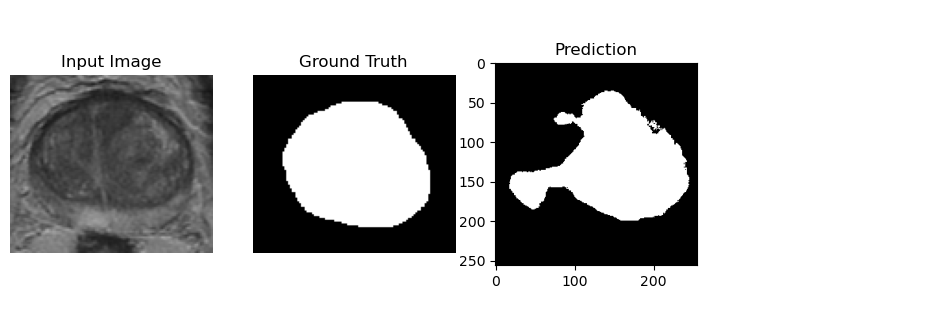

Pred shape: torch.Size([256, 256])


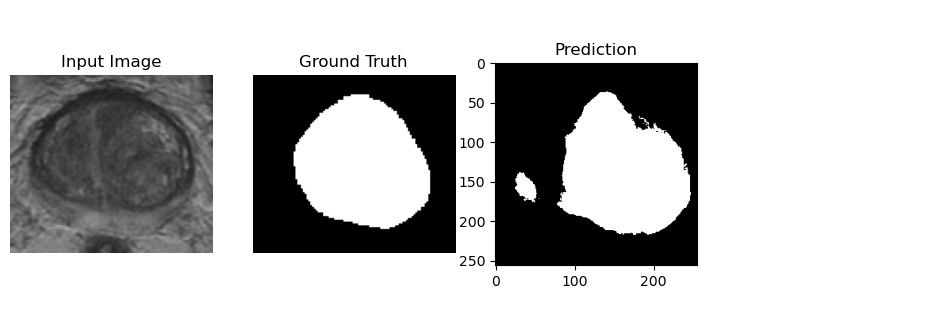

Pred shape: torch.Size([256, 256])


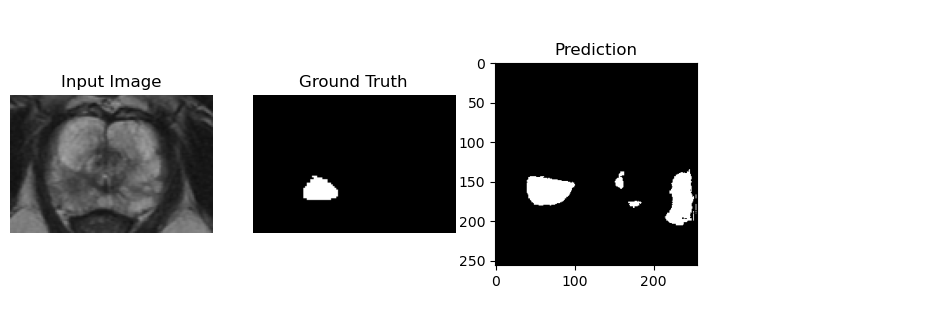

In [32]:
import matplotlib.pyplot as plt

def show_predictions(learn):
    #image, mask = dls.one_batch()
    learn.model.eval()
    for i in range(3):
        image, mask = dls.valid_ds[i]
        #Image shape: (97, 110)
        # Mask shape: (97, 110)
        pred = learn.predict(image)[0]
        print("Pred shape:", pred.shape)
        fig, axs = plt.subplots(1, 4, figsize=(12, 4))
        axs[0].imshow(image, cmap='gray')
        axs[0].set_title('Input Image')
        axs[0].axis('off')
        axs[1].imshow(mask, cmap='gray')
        axs[1].set_title('Ground Truth')
        axs[1].axis('off')
        axs[2].imshow(pred, cmap='gray')
        axs[2].set_title('Prediction')
        axs[3].axis('off')
        plt.show()

show_predictions(learn)

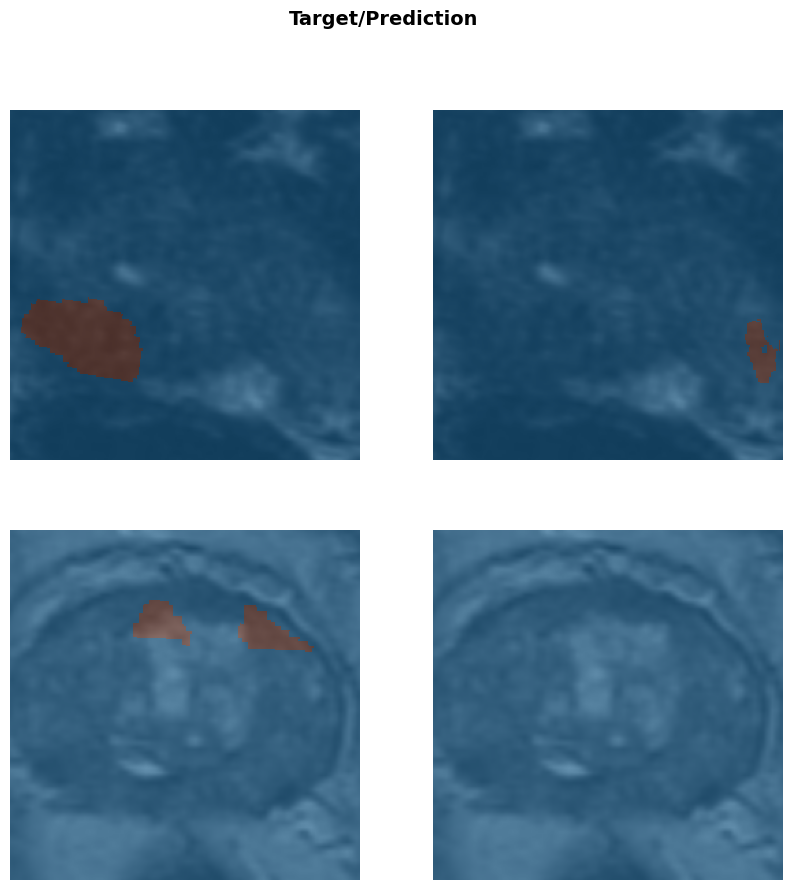

In [33]:
# visualize the results of the training set
learn.show_results(ds_idx=0, max_n=6, figsize=(10, 10))

## Saving the model

In [ ]:
# Save the model
learn.save('2d-unet-prostate-cancer-segmentation')

Path('models/2d-unet-prostate-cancer-segmentation.pth')

## Load the Model

In [29]:
# Load the model later
learn = learn.load('unet-model-unfrozen') # or '2d-unet-prostate-cancer-segmentation', it's the same, just to make sure to save it

/home/marina/anaconda3/envs/semtorch/lib/python3.9/site-packages/fastai/learner.py:61: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")


In [30]:
model = learn.model

In [31]:
for images, masks in dls.train:
    print(f"Images shape: {images.shape}")  # Expected: [2, 3, 256, 256]
    print(f"Masks shape: {masks.shape}")    # Expected: [2, 256, 256]
    print(f"Masks dtype: {masks.dtype}")    # Expected: torch.int64
    print(f"Unique labels in masks: {torch.unique(masks)}")  # Expected: tensor([0, 1])
    break

Images shape: torch.Size([2, 3, 256, 256])
Masks shape: torch.Size([2, 256, 256])
Masks dtype: torch.int64
Unique labels in masks: TensorMask([0, 1])


In [32]:
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def transform_image(image):
    my_transforms = transforms.Compose([transforms.ToTensor(),
                                        transforms.Normalize(
                                            [0.485, 0.456, 0.406],
                                            [0.229, 0.224, 0.225])])
    image_aux = image
    return my_transforms(image_aux).unsqueeze(0).to(device)

In [33]:
class BackgroundDice:
    def __init__(self):
        self.dice_score = 0
        self.count = 0

    def accumulate(self, predicted, masks):
        # Assume that the predicted and masks are class indices
        # For background, class index is 0
        predicted_class = (predicted == 0).float()  # Background (class 0)
        masks_class = (masks == 0).float()  # Background (class 0)

        intersection = (predicted_class * masks_class).sum()
        union = predicted_class.sum() + masks_class.sum()

        if union != 0:
            dice = 2 * intersection / union
        else:
            dice = 1.0  # if no intersection, we consider it perfect match

        self.dice_score += dice
        self.count += 1

    @property
    def value(self):
        return self.dice_score / self.count if self.count > 0 else 0


class CancerDice:
    def __init__(self):
        self.dice_score = 0
        self.count = 0

    def accumulate(self, predicted, masks):
        # For cancer, class index is 1
        predicted_class = (predicted == 1).float()  # Cancer (class 1)
        masks_class = (masks == 1).float()  # Cancer (class 1)

        intersection = (predicted_class * masks_class).sum()
        union = predicted_class.sum() + masks_class.sum()

        if union != 0:
            dice = 2 * intersection / union
        else:
            dice = 1.0  # if no intersection, we consider it perfect match

        self.dice_score += dice
        self.count += 1

    @property
    def value(self):
        return self.dice_score / self.count if self.count > 0 else 0

class BackgroundAcc:
    def __init__(self):
        self.correct = 0
        self.total = 0

    def accumulate(self, predicted, masks):
        # For background, class index is 0
        predicted_class = (predicted == 0).float()
        masks_class = (masks == 0).float()

        # Count only where mask is actually background:
        self.correct += (predicted_class * masks_class).sum().item()  
        self.total += masks_class.sum().item()

    @property
    def value(self):
        return self.correct / self.total if self.total > 0 else 0


class CancerAcc:
    def __init__(self):
        self.correct = 0
        self.total = 0

    def accumulate(self, predicted, masks):
        # For cancer, class index is 1
        predicted_class = (predicted == 1).float()
        masks_class = (masks == 1).float()

        # Count only where mask is actually cancer:
        self.correct += (predicted_class * masks_class).sum().item()
        self.total += masks_class.sum().item()

    @property
    def value(self):
        return self.correct / self.total if self.total > 0 else 0

def get_metrics(model, dls):
    model.eval()

    # Initialize metrics for both classes
    background_dice = BackgroundDice()
    cancer_dice = CancerDice()
    background_acc = BackgroundAcc()
    cancer_acc = CancerAcc()

    with torch.no_grad():  # Avoid tracking gradients during inference
        for images, masks in dls.valid:
            images = images.to(device)
            masks = masks.to(device)
            outputs = model(images)

            # Assuming outputs are logits, apply argmax to get predicted labels
            _, predicted = torch.max(outputs, 1)  # Predicted: [batch_size, height, width]

            # Accumulate metrics for background and cancer classes
            background_dice.accumulate(predicted, masks)  # Background (class 0)
            cancer_dice.accumulate(predicted, masks)  # Cancer (class 1)

            background_acc.accumulate(predicted, masks)  # Background
            cancer_acc.accumulate(predicted, masks)  # Cancer
    
    # Return metrics dictionary
    return {
        'Background Dice': TensorMask(background_dice.value),  # Assuming TensorMask class or similar
        'Cancer Dice': TensorMask(cancer_dice.value),  # Assuming TensorMask class or similar
        'Background Accuracy': TensorMask(background_acc.value),  # Using TensorMask-like format
        'Cancer Accuracy': TensorMask(cancer_acc.value)  # Using TensorMask-like format
    }

# Example usage
metrics = get_metrics(model, dls)
print(metrics)

{'Background Dice': TensorMask(0.9507), 'Cancer Dice': TensorMask(0.4726), 'Background Accuracy': TensorMask(0.9686), 'Cancer Accuracy': TensorMask(0.5575)}


In [29]:
# find the best threshold for the prediction
def find_best_threshold(learn, dls):
    learn.model.eval()
    thresholds = torch.linspace(0.1, 0.9, 9)
    best_threshold = None
    best_dice = 0.0
    for threshold in thresholds:
        dice = 0.0
        for image, mask in dls.valid_ds:
            mask = transforms.Resize((256, 256))(mask)
            mask = transforms.ToTensor()(mask)
            pred = learn.predict(image)[0]
            pred = (pred > threshold).float()
            dice += (2 * (pred * mask).sum() + 1e-8) / (pred.sum() + mask.sum() + 1e-8)
        dice /= len(dls.valid_ds)
        if dice > best_dice:
            best_dice = dice
            best_threshold = threshold
    return best_threshold, best_dice

best_threshold, best_dice = find_best_threshold(learn, dls)
print(f"Best threshold: {best_threshold}, Best Dice: {best_dice}")

Best threshold: 0.10000000149011612, Best Dice: TensorMask(0.0030)


In [88]:
def prediction(path):
    img = Image.open(path)
    #  output with shape [1, 64, 89] doesn't match the broadcast shape [3, 64, 89]
    # we need to transform the image to the right shape, RGB
    img = img.convert('RGB')
    tensor = transform_image(img)
    
    model.to(device)
    with torch.no_grad():
        outputs = model(tensor)

    # outputs = torch.argmax(outputs,1) # shape [1, 64, 89]
    # we don't want the threshold to be 0.5, we want the best threshold = 0.1
    print("outputs shape:", outputs.shape)
    #print("outputs tipo:", type(outputs))
    outputs = outputs.squeeze(0)
    print("outputs shape:", outputs.shape)
    outputs = (outputs[1] > best_threshold).float()
    print("outputs shape:", outputs.shape)
    mask = np.array(outputs.cpu())
    #print(mask.shape) # (1, 480, 480)
    mask[mask > 0] = 255
    mask = mask.squeeze()
    return np.array(transforms.Resize(img.shape)(Image.fromarray(mask.astype('uint8'))))

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_37_slice_16.png
outputs shape: torch.Size([1, 2, 97, 110])
outputs shape: torch.Size([2, 97, 110])
outputs shape: torch.Size([97, 110])


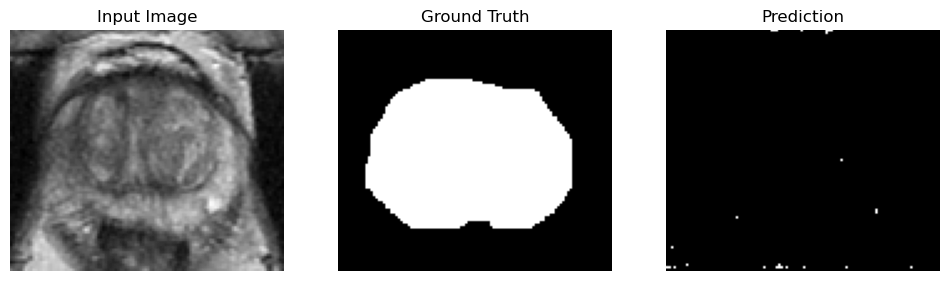

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_43_slice_21.png
outputs shape: torch.Size([1, 2, 134, 136])
outputs shape: torch.Size([2, 134, 136])
outputs shape: torch.Size([134, 136])


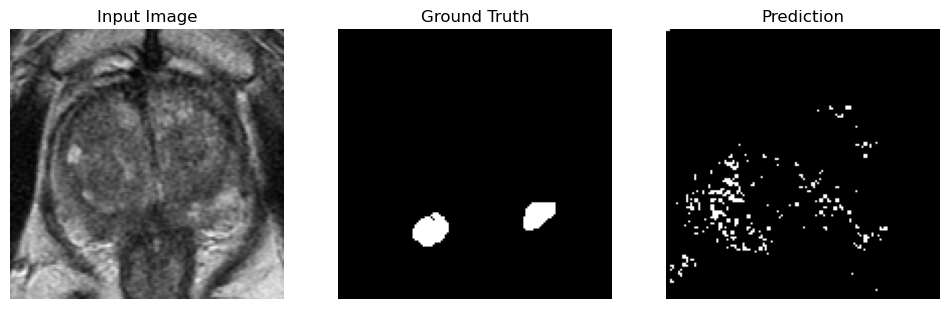

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_34_slice_15.png
outputs shape: torch.Size([1, 2, 71, 111])
outputs shape: torch.Size([2, 71, 111])
outputs shape: torch.Size([71, 111])


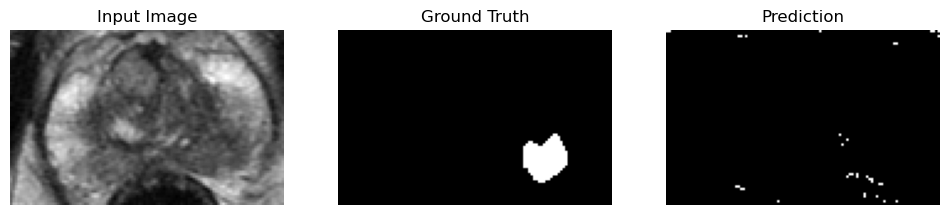

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_30_slice_19.png
outputs shape: torch.Size([1, 2, 96, 89])
outputs shape: torch.Size([2, 96, 89])
outputs shape: torch.Size([96, 89])


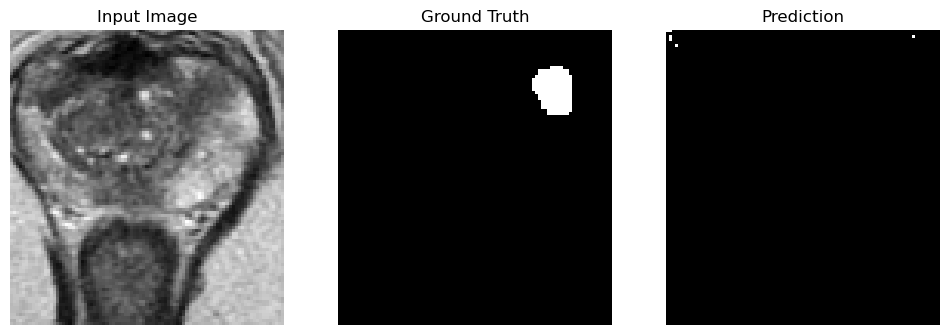

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_46_slice_22.png
outputs shape: torch.Size([1, 2, 80, 103])
outputs shape: torch.Size([2, 80, 103])
outputs shape: torch.Size([80, 103])


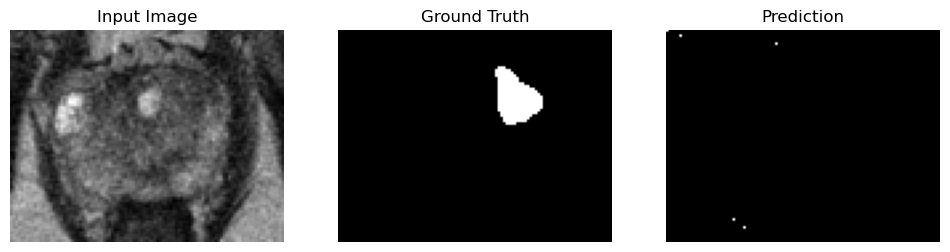

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_60_slice_17.png
outputs shape: torch.Size([1, 2, 71, 93])
outputs shape: torch.Size([2, 71, 93])
outputs shape: torch.Size([71, 93])


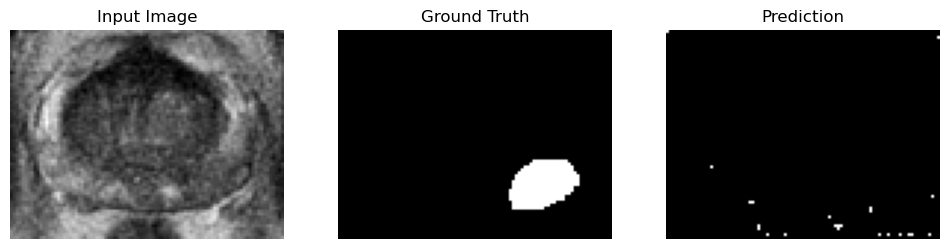

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_12_slice_21.png
outputs shape: torch.Size([1, 2, 92, 109])
outputs shape: torch.Size([2, 92, 109])
outputs shape: torch.Size([92, 109])


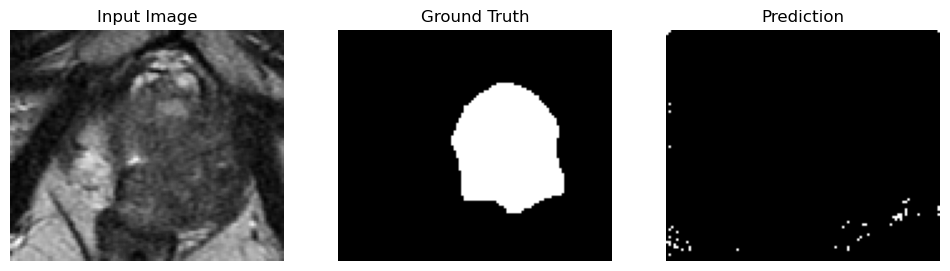

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_32_slice_11.png
outputs shape: torch.Size([1, 2, 89, 103])
outputs shape: torch.Size([2, 89, 103])
outputs shape: torch.Size([89, 103])


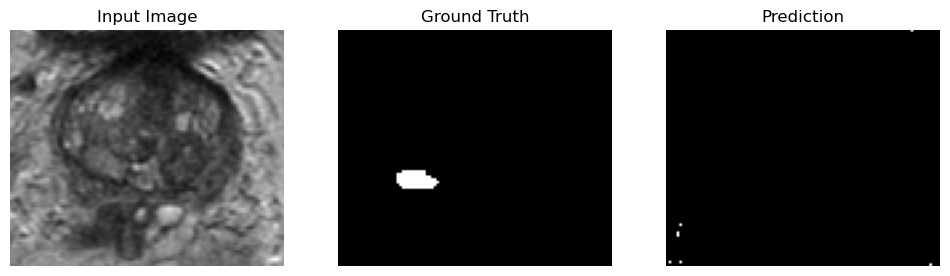

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_63_slice_20.png
outputs shape: torch.Size([1, 2, 109, 98])
outputs shape: torch.Size([2, 109, 98])
outputs shape: torch.Size([109, 98])


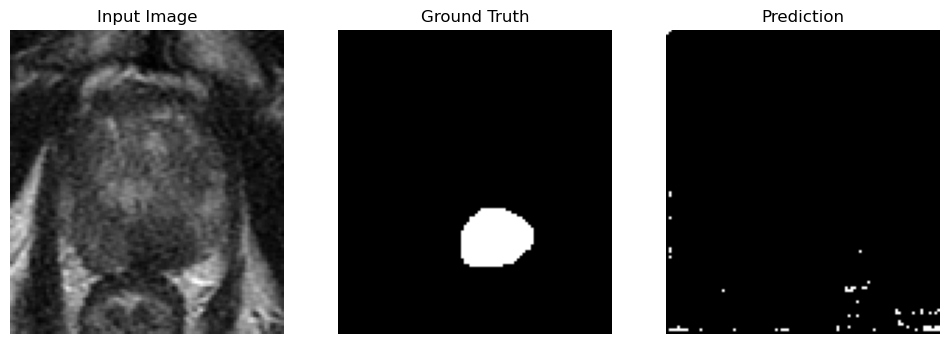

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_64_slice_25.png
outputs shape: torch.Size([1, 2, 140, 120])
outputs shape: torch.Size([2, 140, 120])
outputs shape: torch.Size([140, 120])


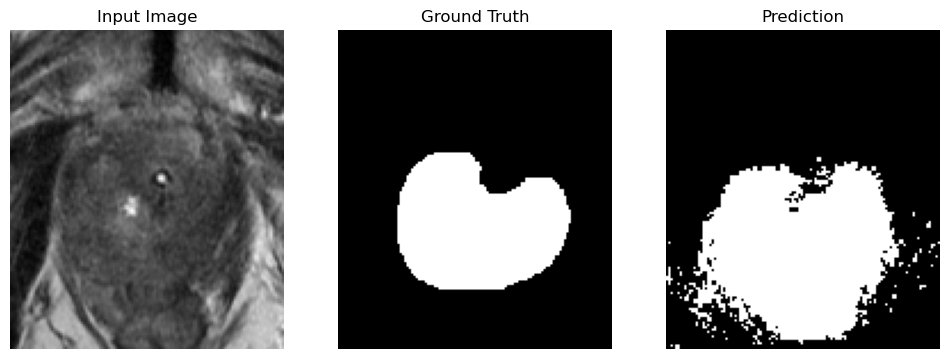

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_64_slice_16.png
outputs shape: torch.Size([1, 2, 140, 120])
outputs shape: torch.Size([2, 140, 120])
outputs shape: torch.Size([140, 120])


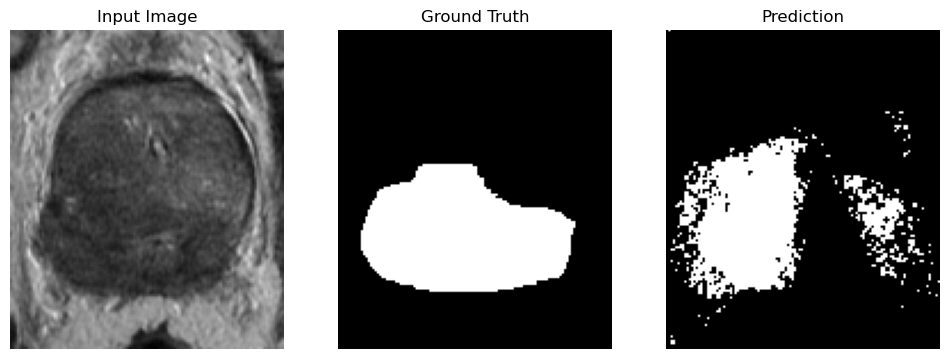

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_59_slice_17.png
outputs shape: torch.Size([1, 2, 80, 88])
outputs shape: torch.Size([2, 80, 88])
outputs shape: torch.Size([80, 88])


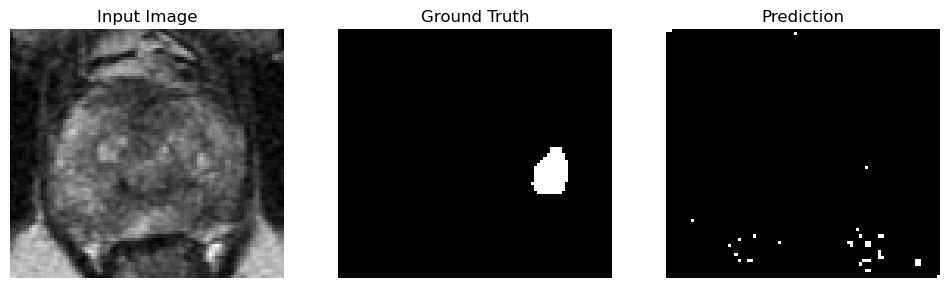

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_37_slice_9.png
outputs shape: torch.Size([1, 2, 97, 110])
outputs shape: torch.Size([2, 97, 110])
outputs shape: torch.Size([97, 110])


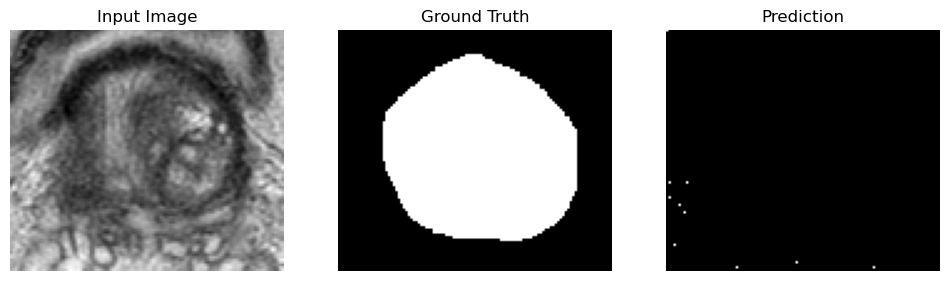

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_0_slice_16.png
outputs shape: torch.Size([1, 2, 64, 89])
outputs shape: torch.Size([2, 64, 89])
outputs shape: torch.Size([64, 89])


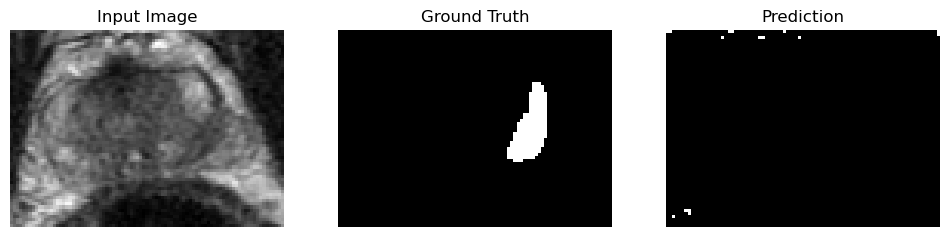

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_37_slice_10.png
outputs shape: torch.Size([1, 2, 97, 110])
outputs shape: torch.Size([2, 97, 110])
outputs shape: torch.Size([97, 110])


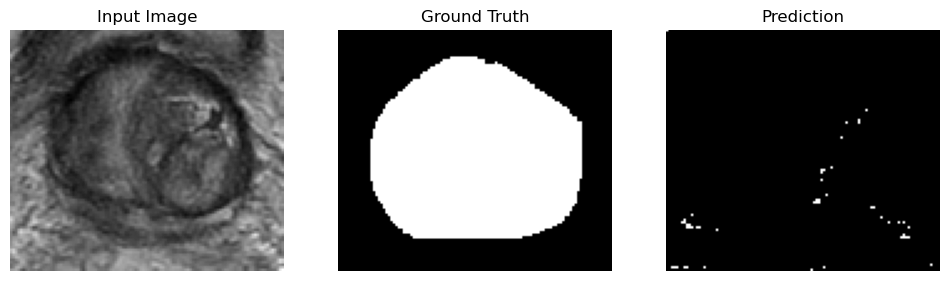

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_4_slice_19.png
outputs shape: torch.Size([1, 2, 84, 94])
outputs shape: torch.Size([2, 84, 94])
outputs shape: torch.Size([84, 94])


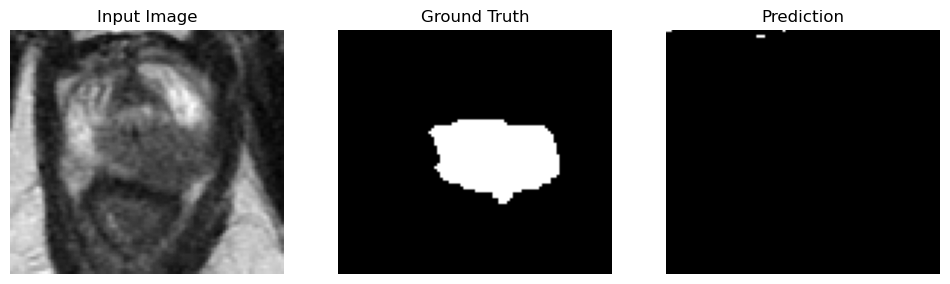

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_27_slice_20.png
outputs shape: torch.Size([1, 2, 71, 94])
outputs shape: torch.Size([2, 71, 94])
outputs shape: torch.Size([71, 94])


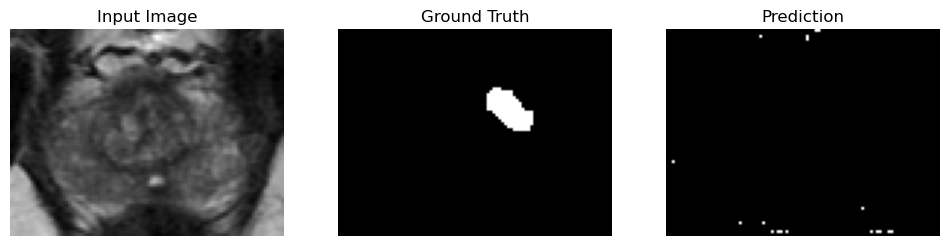

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_13_slice_12.png
outputs shape: torch.Size([1, 2, 99, 113])
outputs shape: torch.Size([2, 99, 113])
outputs shape: torch.Size([99, 113])


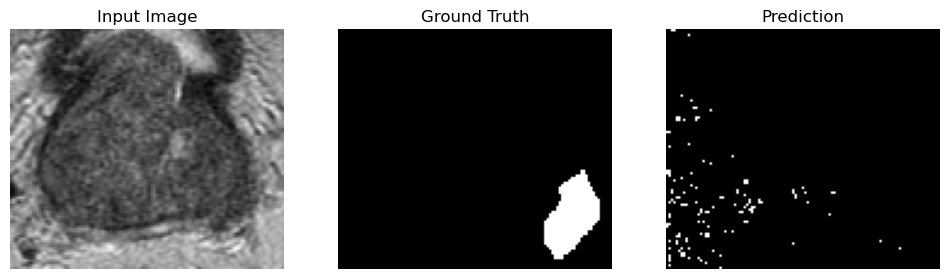

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_12_slice_17.png
outputs shape: torch.Size([1, 2, 92, 109])
outputs shape: torch.Size([2, 92, 109])
outputs shape: torch.Size([92, 109])


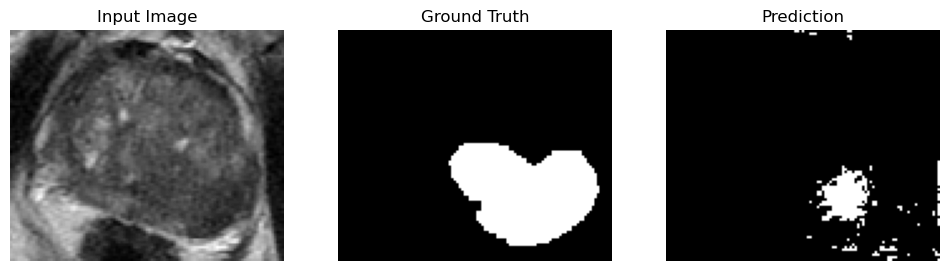

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_31_slice_17.png
outputs shape: torch.Size([1, 2, 106, 98])
outputs shape: torch.Size([2, 106, 98])
outputs shape: torch.Size([106, 98])


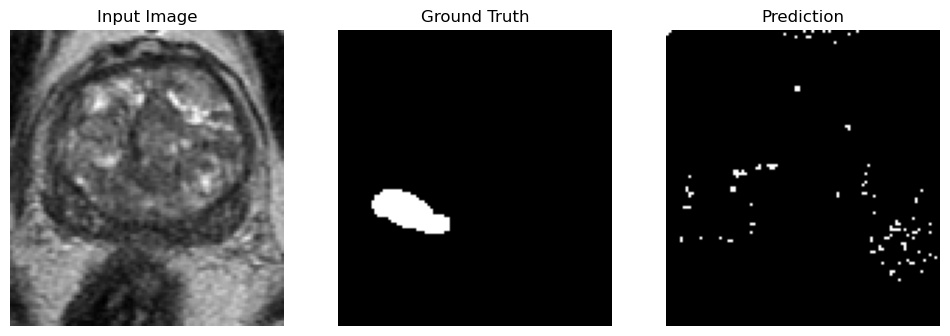

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_20_slice_11.png
outputs shape: torch.Size([1, 2, 83, 99])
outputs shape: torch.Size([2, 83, 99])
outputs shape: torch.Size([83, 99])


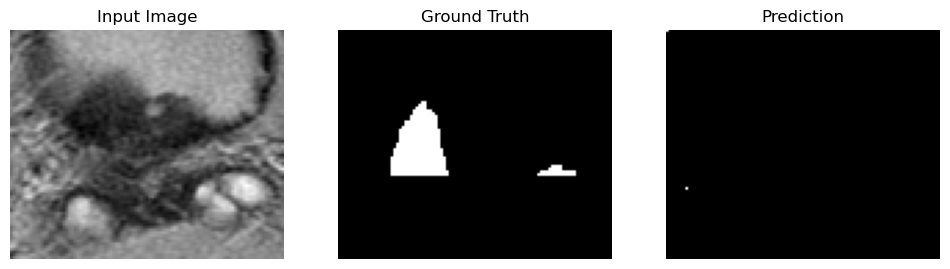

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_12_slice_19.png
outputs shape: torch.Size([1, 2, 92, 109])
outputs shape: torch.Size([2, 92, 109])
outputs shape: torch.Size([92, 109])


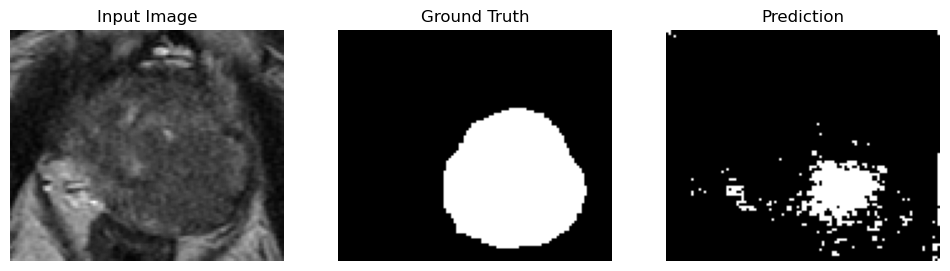

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_56_slice_19.png
outputs shape: torch.Size([1, 2, 97, 124])
outputs shape: torch.Size([2, 97, 124])
outputs shape: torch.Size([97, 124])


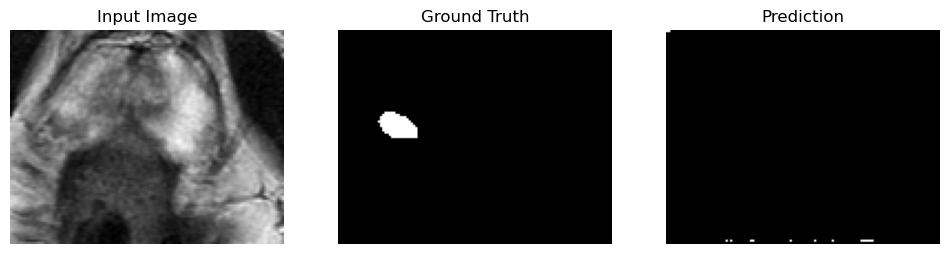

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_63_slice_15.png
outputs shape: torch.Size([1, 2, 109, 98])
outputs shape: torch.Size([2, 109, 98])
outputs shape: torch.Size([109, 98])


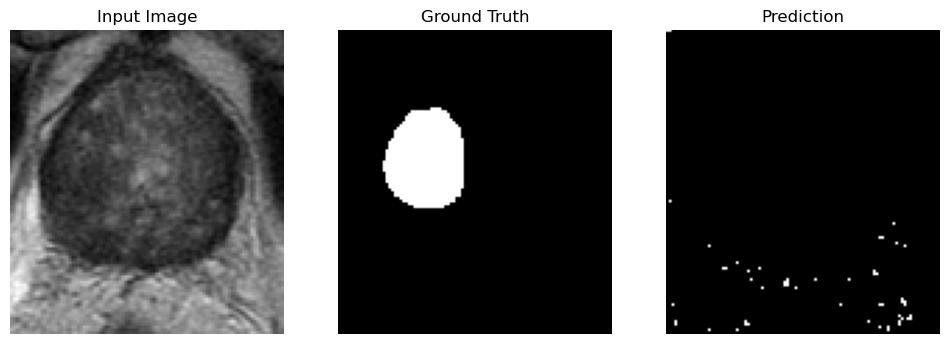

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_31_slice_16.png
outputs shape: torch.Size([1, 2, 106, 98])
outputs shape: torch.Size([2, 106, 98])
outputs shape: torch.Size([106, 98])


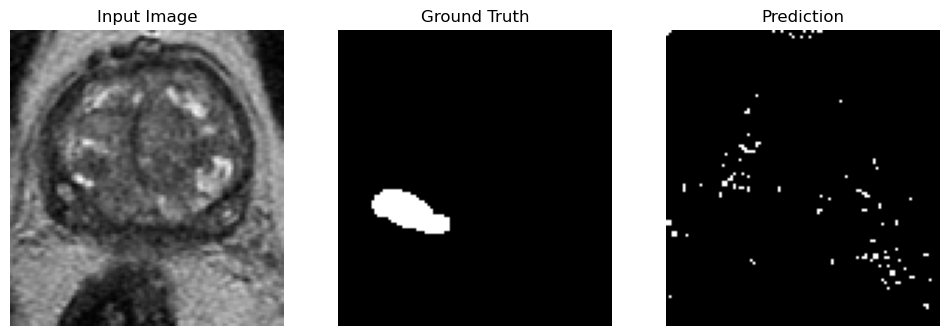

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_12_slice_22.png
outputs shape: torch.Size([1, 2, 92, 109])
outputs shape: torch.Size([2, 92, 109])
outputs shape: torch.Size([92, 109])


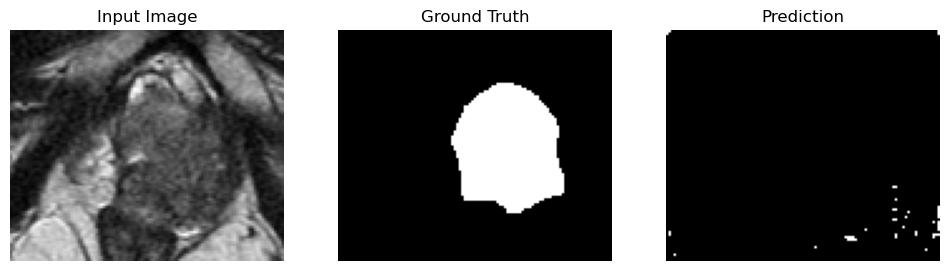

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_22_slice_18.png
outputs shape: torch.Size([1, 2, 76, 106])
outputs shape: torch.Size([2, 76, 106])
outputs shape: torch.Size([76, 106])


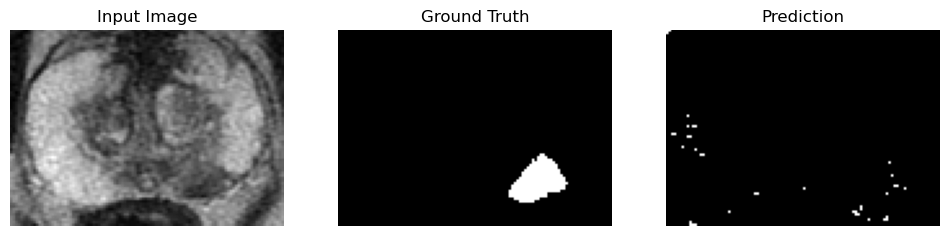

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_36_slice_21.png
outputs shape: torch.Size([1, 2, 81, 109])
outputs shape: torch.Size([2, 81, 109])
outputs shape: torch.Size([81, 109])


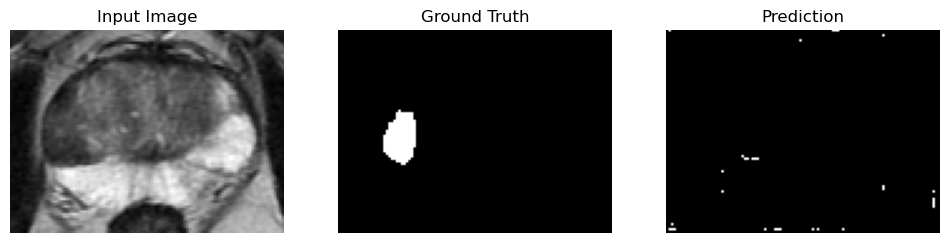

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_9_slice_17.png
outputs shape: torch.Size([1, 2, 72, 94])
outputs shape: torch.Size([2, 72, 94])
outputs shape: torch.Size([72, 94])


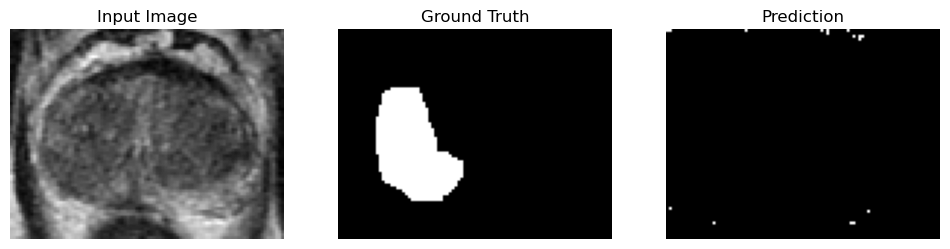

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_36_slice_20.png
outputs shape: torch.Size([1, 2, 81, 109])
outputs shape: torch.Size([2, 81, 109])
outputs shape: torch.Size([81, 109])


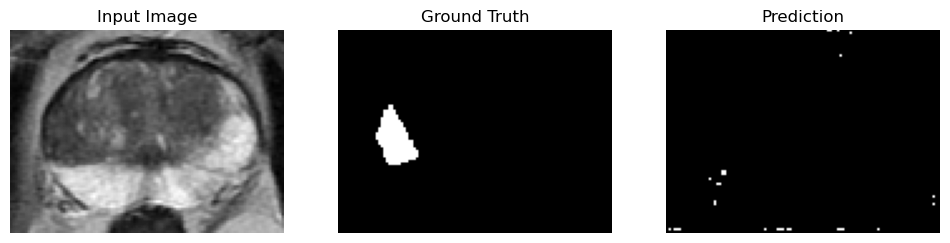

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_61_slice_13.png
outputs shape: torch.Size([1, 2, 67, 97])
outputs shape: torch.Size([2, 67, 97])
outputs shape: torch.Size([67, 97])


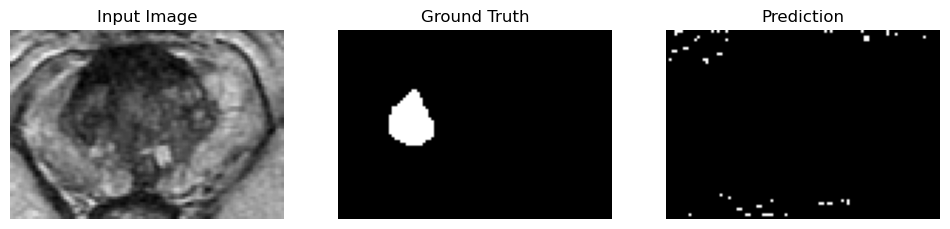

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_20_slice_14.png
outputs shape: torch.Size([1, 2, 83, 99])
outputs shape: torch.Size([2, 83, 99])
outputs shape: torch.Size([83, 99])


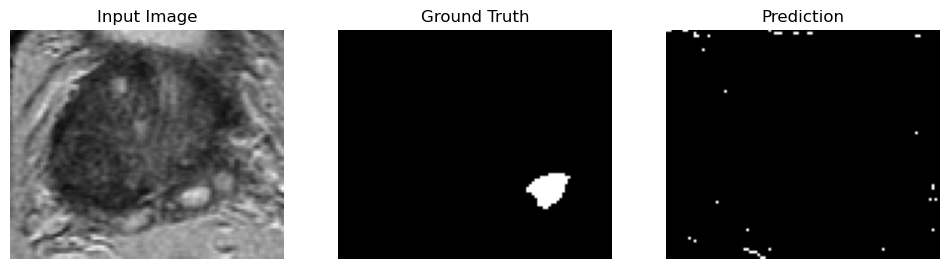

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_59_slice_15.png
outputs shape: torch.Size([1, 2, 80, 88])
outputs shape: torch.Size([2, 80, 88])
outputs shape: torch.Size([80, 88])


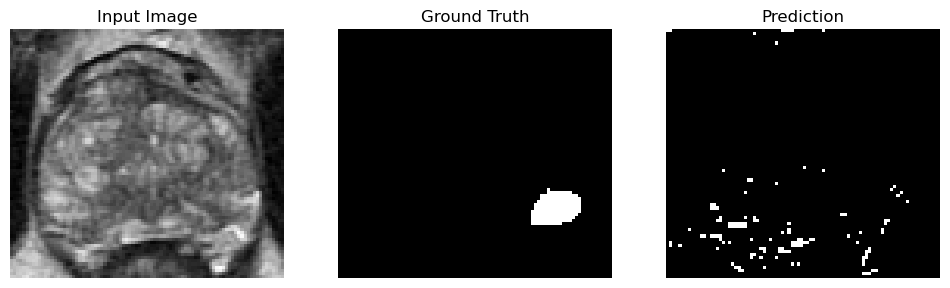

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_20_slice_16.png
outputs shape: torch.Size([1, 2, 83, 99])
outputs shape: torch.Size([2, 83, 99])
outputs shape: torch.Size([83, 99])


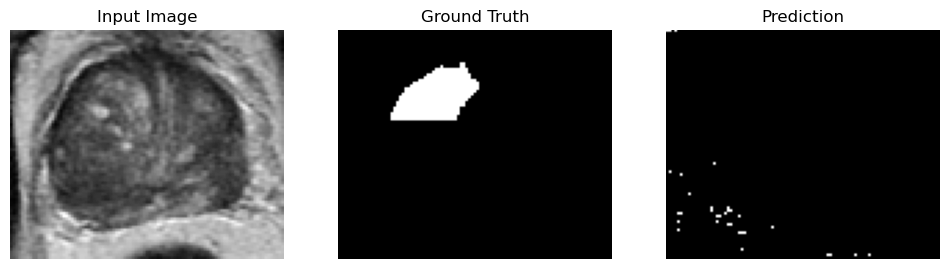

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_55_slice_14.png
outputs shape: torch.Size([1, 2, 63, 104])
outputs shape: torch.Size([2, 63, 104])
outputs shape: torch.Size([63, 104])


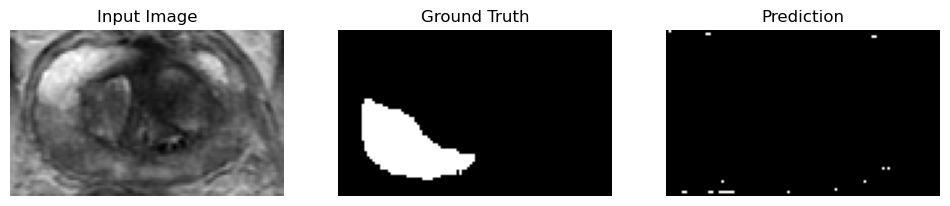

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_64_slice_15.png
outputs shape: torch.Size([1, 2, 140, 120])
outputs shape: torch.Size([2, 140, 120])
outputs shape: torch.Size([140, 120])


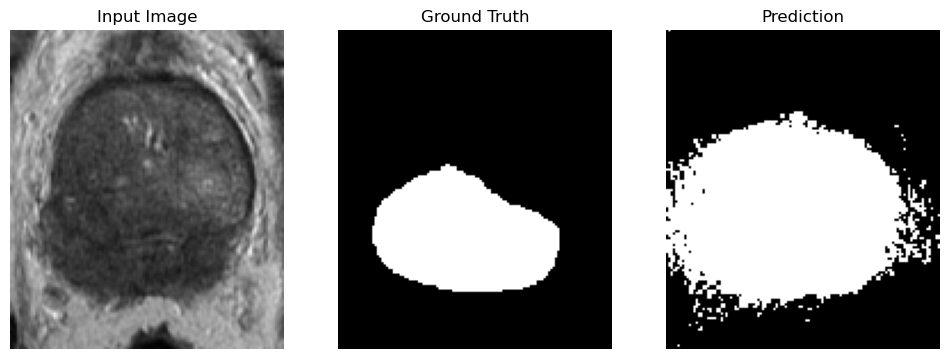

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_31_slice_20.png
outputs shape: torch.Size([1, 2, 106, 98])
outputs shape: torch.Size([2, 106, 98])
outputs shape: torch.Size([106, 98])


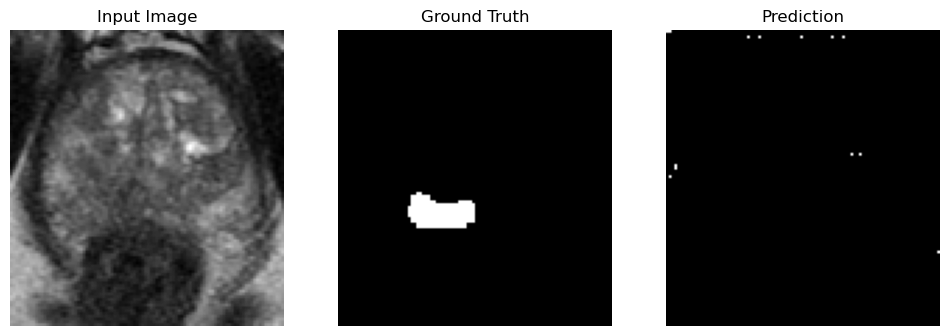

/home/marina/Escritorio/Task05_Prostate/HOSP_pipeline/dataset/onlylabelled_organized_dataset_segment/images/test/patient_62_slice_14.png
outputs shape: torch.Size([1, 2, 87, 111])
outputs shape: torch.Size([2, 87, 111])
outputs shape: torch.Size([87, 111])


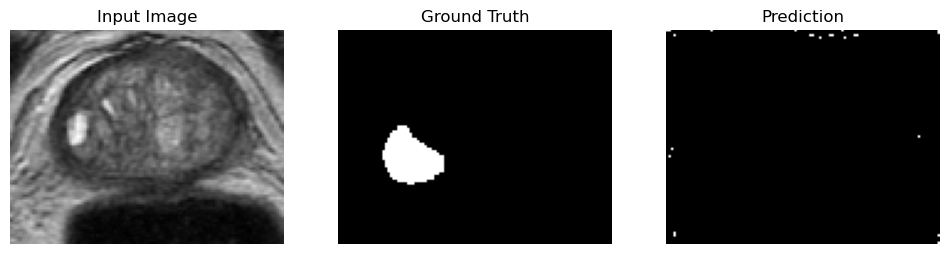

In [92]:
best_threshold = 0.1
for images in list((path / 'images' / 'test').rglob('*.*')):
    print(images)
    mask = path / 'masks' / 'test' / f"{images.stem}_label{images.suffix}"
    mask = np.array(Image.open(mask))
    pred = prediction(images)
    fig, axs = plt.subplots(1, 3, figsize=(12, 6))
    plt.subplot(1, 3, 1)
    plt.imshow(Image.open(images), cmap='gray')
    plt.axis('off')
    plt.title('Input Image')
    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap='gray')
    plt.axis('off')
    plt.title('Ground Truth')
    plt.subplot(1, 3, 3)
    plt.imshow(pred, cmap='gray')
    plt.axis('off')
    plt.title('Prediction')
    plt.show()